<a href="https://colab.research.google.com/github/AjayKumar22633/US_Alberta_WildLife_Clasification_CNN/blob/main/Alberta_wildlife_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [199]:
import pandas as pd
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

In [200]:
import os
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

In [201]:
torch.manual_seed(42)

In [202]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [203]:
import os
df = '/content/drive/MyDrive/Colab Notebooks/bald_eagle','/content/drive/MyDrive/Colab Notebooks/bighorn_sheep','/content/drive/MyDrive/Colab Notebooks/bison','/content/drive/MyDrive/Colab Notebooks/black_bear','/content/drive/MyDrive/Colab Notebooks/burrowing_owl','/content/drive/MyDrive/Colab Notebooks/canada_goose_bird','/content/drive/MyDrive/Colab Notebooks/caribou','/content/drive/MyDrive/Colab Notebooks/cougar','/content/drive/MyDrive/Colab Notebooks/elk','/content/drive/MyDrive/Colab Notebooks/golden_eagle','/content/drive/MyDrive/Colab Notebooks/great_horned_owl','/content/drive/MyDrive/Colab Notebooks/grizzly_bear','/content/drive/MyDrive/Colab Notebooks/lynx','/content/drive/MyDrive/Colab Notebooks/moose','/content/drive/MyDrive/Colab Notebooks/mountain_goat','/content/drive/MyDrive/Colab Notebooks/mule_deer','/content/drive/MyDrive/Colab Notebooks/pine_marten','/content/drive/MyDrive/Colab Notebooks/river_otter','/content/drive/MyDrive/Colab Notebooks/snow_goose','/content/drive/MyDrive/Colab Notebooks/white_tail_deer'


In [204]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"using' device: {device}")

using' device: cuda


In [205]:
import numpy as np
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import LabelEncoder

paths, raw_labels = [], []
for folder in df:
  cls = os.path.basename(folder)
  for f in sorted(os.listdir(folder)):
    if f.lower().endswith(('.jpg', '.jpg', '.png')):
      paths.append(os.path.join(folder,f))
      raw_labels.append(cls)
le = LabelEncoder()
labels = le.fit_transform(raw_labels)
print(dict(zip(le.classes_, np.bincount(labels))))

{np.str_('bald_eagle'): np.int64(98), np.str_('bighorn_sheep'): np.int64(100), np.str_('bison'): np.int64(100), np.str_('black_bear'): np.int64(100), np.str_('burrowing_owl'): np.int64(100), np.str_('canada_goose_bird'): np.int64(100), np.str_('caribou'): np.int64(100), np.str_('cougar'): np.int64(100), np.str_('elk'): np.int64(100), np.str_('golden_eagle'): np.int64(100), np.str_('great_horned_owl'): np.int64(100), np.str_('grizzly_bear'): np.int64(100), np.str_('lynx'): np.int64(100), np.str_('moose'): np.int64(100), np.str_('mountain_goat'): np.int64(100), np.str_('mule_deer'): np.int64(100), np.str_('pine_marten'): np.int64(86), np.str_('river_otter'): np.int64(100), np.str_('snow_goose'): np.int64(100), np.str_('white_tail_deer'): np.int64(100)}


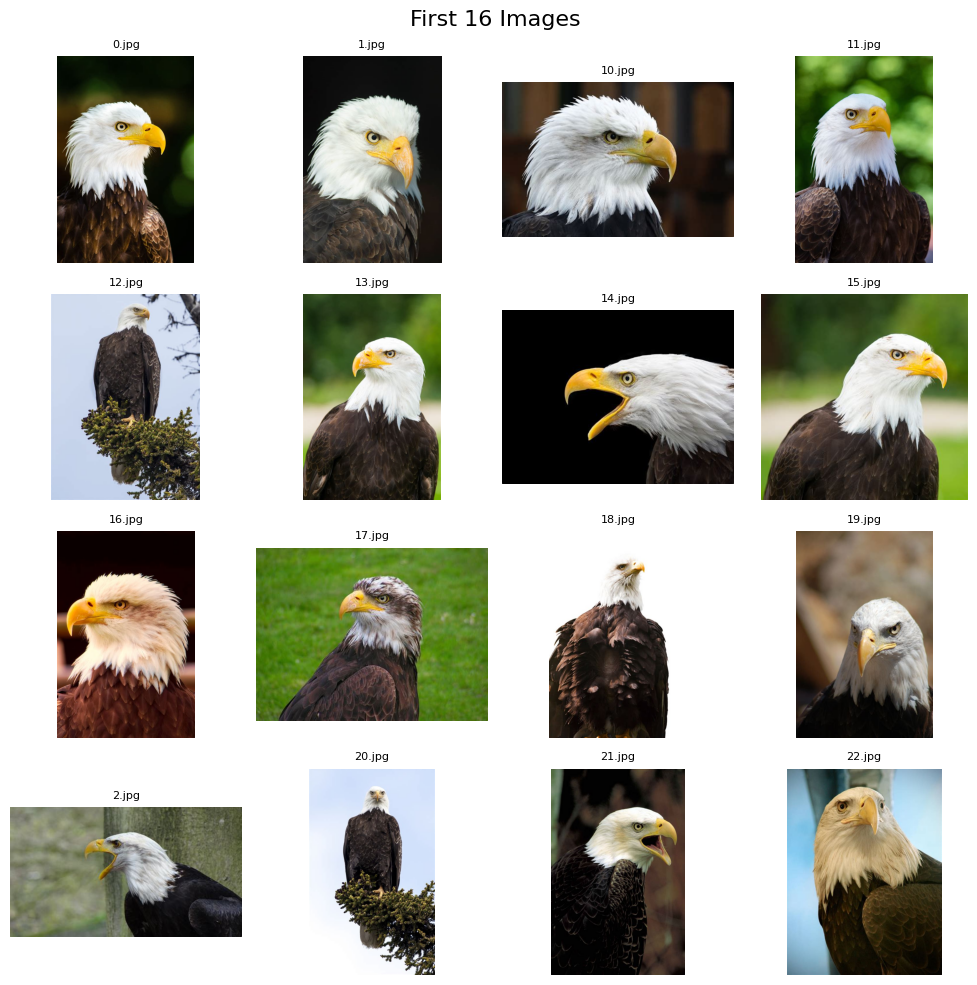

In [206]:
import os
from PIL import Image
import matplotlib.pyplot as plt

# Collect the first 16 image paths from the folders in df
image_paths = []
for folder in df:
    for fname in sorted(os.listdir(folder)):
        if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
            image_paths.append(os.path.join(folder, fname))
            if len(image_paths) >= 16:
                break
    if len(image_paths) >= 16:
        break

# Plot the images
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
fig.suptitle("First 16 Images", fontsize=16)
for ax, img_path in zip(axes.flat, image_paths):
    img = Image.open(img_path)
    ax.imshow(img, cmap='gray')
    ax.set_title(os.path.basename(img_path)[:12], fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [207]:
#for import figure dataset file
import os
from sklearn.model_selection import train_test_split

files = []
paths = []
labels = []

# Loop through each folder in the df tuple to collect files, paths, and labels
for folder in df:
    # Correctly use the folder name (animal species) as the class label instead of the filename prefix
    class_label = os.path.basename(folder)
    folder_files = sorted(os.listdir(folder))
    for f in folder_files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            files.append(f)
            paths.append(os.path.join(folder, f))
            labels.append(class_label)

print("Sample files:", files[:10])
print("Unique labels found:", set(labels))

Sample files: ['0.jpg', '1.jpg', '10.jpg', '11.jpg', '12.jpg', '13.jpg', '14.jpg', '15.jpg', '16.jpg', '17.jpg']
Unique labels found: {'river_otter', 'snow_goose', 'elk', 'bighorn_sheep', 'lynx', 'bald_eagle', 'burrowing_owl', 'golden_eagle', 'great_horned_owl', 'pine_marten', 'cougar', 'mountain_goat', 'moose', 'canada_goose_bird', 'white_tail_deer', 'caribou', 'mule_deer', 'grizzly_bear', 'black_bear', 'bison'}


In [208]:
#train test split
x_train, x_test, y_train, y_test = train_test_split(
    paths, labels, test_size=0.2, random_state=42, stratify=labels
)
print(len(x_train), len(x_test))

1587 397


In [209]:
#load images into arrays
import numpy as np
from PIL import Image
def load_images(path_list, size=(128, 128)):
  imgs = []
  for p in path_list:
    img = Image.open(p).convert('L').resize(size)
    imgs.append(np.array(img))
  return np.array(imgs)

In [210]:
#scaling the features
x_train = load_images(x_train) / 255.0
x_test = load_images(x_test) / 255.0
print(x_train.shape, x_test.shape)

(1587, 128, 128) (397, 128, 128)


In [211]:
#create custom Dataset class
import torch
from torch.utils.data import Dataset, DataLoader

class CustomDataset(Dataset):
    def __init__(self, features, labels):
       self.features = torch.tensor(features, dtype=torch.float32).reshape(-1,1,28,28).unsqueeze(1)
       self.labels = torch.tensor(labels, dtype=torch.long)
    def __len__(self):
       return len(self.features)
    def __getitem__(self, index):
       return self.features[index], self.labels[index]

In [212]:
from sklearn.preprocessing import LabelEncoder
import torch
from torch.utils.data import Dataset
from sklearn.model_selection import train_test_split

# Redefine CustomDataset to use the correct image size (128x128)
class CustomDataset(Dataset):
    def __init__(self, features, labels):
       # Since images are (128, 128), we reshape them to (-1, 1, 128, 128)
       self.features = torch.tensor(features, dtype=torch.float32).reshape(-1, 1, 128, 128)
       self.labels = torch.tensor(labels, dtype=torch.long)
    def __len__(self):
       return len(self.features)
    def __getitem__(self, index):
       return self.features[index], self.labels[index]

# Re-split labels to restore y_train and y_test to their original string state (folder names)
_, _, y_train_orig, y_test_orig = train_test_split(
    paths, labels, test_size=0.2, random_state=42, stratify=labels
)

# Fit and transform safely on original string labels
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train_orig)
y_test_enc = le.transform(y_test_orig)

# Instantiate the custom datasets
train_dataset = CustomDataset(x_train, y_train_enc)
test_dataset = CustomDataset(x_test, y_test_enc)

print(f"Train dataset size: {len(train_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

x0, y0 = train_dataset[0]
print(f"Sample shape: {x0.shape}, label index: {y0}, label name: {le.classes_[y0]}")

Train dataset size: 1587
Test dataset size: 397
Sample shape: torch.Size([1, 128, 128]), label index: 14, label name: mountain_goat


In [213]:
import torchvision.transforms as transforms

# Define data augmentation for training
train_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
])

# Only convert to tensor for evaluation (no augmentation)
test_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
])

In [214]:
# Redefine CustomDataset to apply transforms
class CustomDatasetWithTransforms(Dataset):
    def __init__(self, features, labels, transform=None):
       self.features = features
       self.labels = torch.tensor(labels, dtype=torch.long)
       self.transform = transform

    def __len__(self):
       return len(self.features)

    def __getitem__(self, index):
       # Convert to float32 numpy array and scale to [0, 1] range if not scaled yet
       feature = self.features[index]

       if self.transform:
           # Convert array to scale/type expected by PyTorch transforms
           feature = (feature * 255.0).astype(np.uint8)
           feature = self.transform(feature)
       else:
           feature = torch.tensor(feature, dtype=torch.float32).unsqueeze(0)

       return feature, self.labels[index]

# Re-instantiate our datasets with the new transforms
train_dataset = CustomDatasetWithTransforms(x_train, y_train_enc, transform=train_transform)
test_dataset = CustomDatasetWithTransforms(x_test, y_test_enc, transform=test_transform)

# Recreate our DataLoaders
train_loader = DataLoader(train_dataset, batch_size=138, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=138, shuffle=False)

print("Recreated datasets with transforms successfully!")

Recreated datasets with transforms successfully!


In [215]:
import torchvision.models as models

def get_resnet18_model(num_classes=20):
    # Load pre-trained ResNet18 model
    weights = models.ResNet18_Weights.DEFAULT
    model = models.resnet18(weights=weights)

    # Modify the first conv layer to accept 1 channel (grayscale) instead of 3 channels
    # ResNet18's original conv1: Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
    original_conv = model.conv1
    model.conv1 = nn.Conv2d(
        in_channels=1,
        out_channels=original_conv.out_channels,
        kernel_size=original_conv.kernel_size,
        stride=original_conv.stride,
        padding=original_conv.padding,
        bias=original_conv.bias
    )

    # Copy weights by averaging over the 3 channels to maintain a reasonable initialization
    with torch.no_grad():
        model.conv1.weight.copy_(original_conv.weight.mean(dim=1, keepdim=True))

    # Replace the final fully connected layer to output class predictions for 20 classes
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, num_classes)

    return model

In [216]:
import torchvision.transforms as transforms

# Advanced and stronger data augmentation
train_transform_strong = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomResizedCrop(128, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485], std=[0.229])  # ImageNet stats scaled for grayscale
])

# Ensure matching normalization for evaluation
test_transform_strong = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485], std=[0.229])
])

# Recreate our datasets and loaders with strong transforms
train_dataset = CustomDatasetWithTransforms(x_train, y_train_enc, transform=train_transform_strong)
test_dataset = CustomDatasetWithTransforms(x_test, y_test_enc, transform=test_transform_strong)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)  # Smaller batch size for better generalization
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [217]:
# Re-instantiate the model
resnet_model = get_resnet18_model(num_classes=20).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(resnet_model.parameters(), lr=0.0003) # Slightly higher initial LR since we have a scheduler

# Learning Rate Scheduler (removed the deprecated verbose argument)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

# Early stopping with a bit more patience to allow learning rate decay to work
early_stopping_resnet = EarlyStopping(patience=10, verbose=True, path='best_resnet18_improved.pt')

epochs = 50

print("Training ResNet18 with advanced training strategies...")
for epoch in range(epochs):
    resnet_model.train()
    total_train_loss = 0
    for batch_features, batch_labels in train_loader:
        batch_features = batch_features.to(device)
        batch_labels = batch_labels.to(device)

        outputs = resnet_model(batch_features)
        loss = criterion(outputs, batch_labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / len(train_loader)

    resnet_model.eval()
    total_val_loss = 0
    with torch.no_grad():
        for batch_features, batch_labels in test_loader:
            batch_features = batch_features.to(device)
            batch_labels = batch_labels.to(device)

            outputs = resnet_model(batch_features)
            loss = criterion(outputs, batch_labels)
            total_val_loss += loss.item()

    avg_val_loss = total_val_loss / len(test_loader)

    # Update LR Scheduler based on validation loss
    scheduler.step(avg_val_loss)

    print(f'Epoch: {epoch + 1} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}')

    # Check early stopping
    early_stopping_resnet(avg_val_loss, resnet_model)

    if early_stopping_resnet.early_stop:
        print("Early stopping triggered!")
        break

# Load best model weights
resnet_model.load_state_dict(torch.load('best_resnet18_improved.pt'))
print("Loaded the best improved ResNet18 model weights!")

Training ResNet18 with advanced training strategies...
Epoch: 1 | Train Loss: 2.0950 | Val Loss: 1.7206
Validation loss decreased (inf --> 1.720649).  Saving model ...
Epoch: 2 | Train Loss: 1.0896 | Val Loss: 1.2294
Validation loss decreased (1.720649 --> 1.229364).  Saving model ...
Epoch: 3 | Train Loss: 0.6624 | Val Loss: 1.0332
Validation loss decreased (1.229364 --> 1.033182).  Saving model ...
Epoch: 4 | Train Loss: 0.4554 | Val Loss: 1.1542
EarlyStopping counter: 1 out of 10
Epoch: 5 | Train Loss: 0.3317 | Val Loss: 1.0360
EarlyStopping counter: 2 out of 10
Epoch: 6 | Train Loss: 0.2569 | Val Loss: 0.9122
Validation loss decreased (1.033182 --> 0.912246).  Saving model ...
Epoch: 7 | Train Loss: 0.2091 | Val Loss: 0.9838
EarlyStopping counter: 1 out of 10
Epoch: 8 | Train Loss: 0.1806 | Val Loss: 1.0516
EarlyStopping counter: 2 out of 10
Epoch: 9 | Train Loss: 0.1621 | Val Loss: 1.1405
EarlyStopping counter: 3 out of 10
Epoch: 10 | Train Loss: 0.1677 | Val Loss: 1.1702
EarlySto

In [220]:
# Re-evaluate the improved ResNet18 model utilizing the proper loaders and evaluation setup
resnet_model.eval()

def get_resnet_accuracy_fixed(loader):
    total = 0
    correct = 0
    with torch.no_grad():
        for batch_features, batch_labels in loader:
            batch_features = batch_features.to(device)
            batch_labels = batch_labels.to(device)
            outputs = resnet_model(batch_features)
            _, predicted = torch.max(outputs, 1)
            total += batch_labels.shape[0]
            correct += (predicted == batch_labels).sum().item()
    return correct / total

test_acc_improved = get_resnet_accuracy_fixed(test_loader)
train_acc_improved = get_resnet_accuracy_fixed(train_loader)

print(f"Improved ResNet18 Train Accuracy: {train_acc_improved:.2%}")
print(f"Improved ResNet18 Test Accuracy: {test_acc_improved:.2%}")

Improved ResNet18 Train Accuracy: 94.52%
Improved ResNet18 Test Accuracy: 71.03%


In [224]:
# Redefine predictions using our best-performing ResNet18 model
def predict_image_resnet(path):
  img = Image.open(path).convert('L').resize((128, 128))
  x = torch.tensor(np.array(img) / 255.0, dtype=torch.float32)
  x = x.unsqueeze(0).unsqueeze(0) # Shape: (1, 1, 128, 128)
  x = x.to(device)

  resnet_model.eval()
  with torch.no_grad():
    out = resnet_model(x)
    probs = torch.softmax(out, dim=1)[0]
    pred = probs.argmax().item()
  return le.classes_[pred], probs[pred].item()

try:
  label, conf = predict_image_resnet('/content/drive/MyDrive/Colab Notebooks/lynx/13.jpg')
  print(f"Predicted Species: {label} ({conf:.1%}) (using ResNet18)")
except Exception as e:
  print("Error:", e)

Predicted Species: lynx (66.2%) (using ResNet18)
